
---
date: "2026-11-13"
date-modified: last-modified
format:
  html:
    toc: true
---


# Estimating Hawkes Processes

**Prerequisites:** [The Hawkes process](hawkes-process.ipynb) · [Likelihood of a point process](conditional-intensity-and-compensator.ipynb#thm-point-process-likelihood) · [Time rescaling](conditional-intensity-and-compensator.ipynb#thm-time-rescaling) · [Maximum likelihood estimation](maximum-likelihood-estimation.ipynb#def-mle)

Given event times $0 < t_1 < \cdots < t_n \le T$, we want the baseline, the kernel and the branching ratio. The standard tool is maximum likelihood, which is exact and efficient when the event times are known. The branching structure gives a second route, the EM algorithm, which also tells us which events were probably triggered by which. When only counts per time bin are available, the moment formulas of the [second-order theorem](hawkes-process.ipynb#thm-hawkes-second-order) give a method-of-moments estimator. Every fit ends with a residual check by time rescaling.

## 1\. The Log-Likelihood

::: {#prp-hawkes-loglik}
## Log-likelihood of a Hawkes process
Let the kernel $\varphi_\theta$ depend on a parameter $\theta$ and put $\Phi_\theta(x) = \int_0^x\varphi_\theta(s)\,ds$. The log-likelihood of $(\mu, \theta)$ given events $t_1 < \cdots < t_n$ on $[0, T]$ (process started at its baseline) is
$$
\ell(\mu, \theta) = \sum_{i=1}^n\log\Big(\mu + \sum_{j < i}\varphi_\theta(t_i - t_j)\Big) - \mu T - \sum_{j=1}^n\Phi_\theta(T - t_j).
$$
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-hawkes-loglik
This is the [point process likelihood](conditional-intensity-and-compensator.ipynb#thm-point-process-likelihood) $\sum_i\log\lambda_{t_i} - \Lambda_T$. The left-continuous intensity at $t_i$ counts only $t_j < t_i$, and $\Lambda_T = \mu T + \sum_j\int_{t_j}^T\varphi_\theta(s - t_j)\,ds = \mu T + \sum_j\Phi_\theta(T - t_j)$. $\blacksquare$
:::

The double sum costs $O(n^2)$ operations. For the exponential kernel it collapses to a recursion.

::: {#prp-exponential-loglik}
## Exponential kernel: $O(n)$ likelihood and gradient
Let $\varphi(t) = \alpha e^{-\beta t}$. Define $A_1 = B_1 = 0$ and, with $\Delta_i = t_i - t_{i-1}$,
$$
A_i = e^{-\beta\Delta_i}(1 + A_{i-1}), \qquad B_i = e^{-\beta\Delta_i}\big(B_{i-1} + \Delta_i(1 + A_{i-1})\big), \qquad i \ge 2 .
$$
Then $A_i = \sum_{j<i}e^{-\beta(t_i - t_j)}$, $B_i = \sum_{j<i}(t_i - t_j)e^{-\beta(t_i - t_j)} = -\partial_\beta A_i$, $\lambda_{t_i} = \mu + \alpha A_i$, and with $s_j = T - t_j$,
$$
\begin{aligned}
\ell &= \sum_i\log(\mu + \alpha A_i) - \mu T - \frac{\alpha}{\beta}\sum_j\big(1 - e^{-\beta s_j}\big), \\
\partial_\mu\ell &= \sum_i\frac{1}{\lambda_{t_i}} - T, \qquad
\partial_\alpha\ell = \sum_i\frac{A_i}{\lambda_{t_i}} - \frac1\beta\sum_j\big(1 - e^{-\beta s_j}\big), \\
\partial_\beta\ell &= -\alpha\sum_i\frac{B_i}{\lambda_{t_i}} + \frac{\alpha}{\beta^2}\sum_j\big(1 - e^{-\beta s_j}\big) - \frac{\alpha}{\beta}\sum_j s_je^{-\beta s_j}.
\end{aligned}
$$
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-exponential-loglik
By induction: if $A_{i-1} = \sum_{j < i-1}e^{-\beta(t_{i-1} - t_j)}$, then
$$
\sum_{j<i}e^{-\beta(t_i - t_j)} = e^{-\beta\Delta_i}\Big(1 + \sum_{j<i-1}e^{-\beta(t_{i-1} - t_j)}\Big) = e^{-\beta\Delta_i}(1 + A_{i-1}).
$$
Similarly, writing $t_i - t_j = \Delta_i + (t_{i-1} - t_j)$ for $j < i-1$ and $t_i - t_{i-1} = \Delta_i$,
$$
\sum_{j<i}(t_i - t_j)e^{-\beta(t_i - t_j)} = e^{-\beta\Delta_i}\Big(\sum_{j<i-1}(t_{i-1} - t_j)e^{-\beta(t_{i-1} - t_j)} + \Delta_i\sum_{j<i-1}e^{-\beta(t_{i-1}-t_j)} + \Delta_i\Big) = e^{-\beta\Delta_i}\big(B_{i-1} + \Delta_iA_{i-1} + \Delta_i\big).
$$
Differentiating $A_i$ term by term gives $\partial_\beta A_i = -B_i$. The formula for $\ell$ is @prp-hawkes-loglik with $\Phi(x) = \frac\alpha\beta(1 - e^{-\beta x})$, and the gradient follows by differentiating, using $\partial_\beta\lambda_{t_i} = -\alpha B_i$ and $\partial_\beta\big[\frac\alpha\beta(1 - e^{-\beta s})\big] = -\frac{\alpha}{\beta^2}(1 - e^{-\beta s}) + \frac\alpha\beta se^{-\beta s}$. $\blacksquare$
:::

## 2\. Structure of the Likelihood

Write the kernel as $\varphi = \alpha\,k_\beta$, with an amplitude $\alpha$ and a shape $k_\beta$ that depends on the remaining parameters (for the exponential kernel $k_\beta(t) = e^{-\beta t}$).

::: {#prp-loglik-concave}
## Concavity in the linear parameters
For fixed $\beta$, $(\mu, \alpha) \mapsto \ell(\mu, \alpha, \beta)$ is concave on $(0, \infty)^2$. If it has a maximizer $(\hat\mu, \hat\alpha)$ with $\hat\mu, \hat\alpha > 0$, then the fitted compensator reproduces the number of events:
$$
\hat\Lambda_T = \hat\mu T + \hat\alpha\sum_j\int_0^{T - t_j}k_\beta(s)\,ds = n .
$$
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-loglik-concave
Each $\lambda_{t_i} = \mu + \alpha\sum_{j<i}k_\beta(t_i - t_j)$ is linear in $(\mu, \alpha)$, so $\log\lambda_{t_i}$ is concave (a concave function of a linear map), and $\Lambda_T$ is linear in $(\mu, \alpha)$. Hence $\ell$ is concave. For the identity, note $\mu\,\partial_\mu\lambda_{t_i} + \alpha\,\partial_\alpha\lambda_{t_i} = \lambda_{t_i}$ and $\mu\,\partial_\mu\Lambda_T + \alpha\,\partial_\alpha\Lambda_T = \Lambda_T$ (both are homogeneous of degree one), so
$$
\mu\,\partial_\mu\ell + \alpha\,\partial_\alpha\ell = \sum_i\frac{\lambda_{t_i}}{\lambda_{t_i}} - \Lambda_T = n - \Lambda_T .
$$
At an interior maximizer both partial derivatives vanish, so $\hat\Lambda_T = n$. $\blacksquare$
:::

So the estimation problem has a convex inner part and a low-dimensional outer part: the **profile log-likelihood** $\ell_p(\beta) = \max_{\mu, \alpha}\ell(\mu, \alpha, \beta)$ is a function of $\beta$ only, and each evaluation is a concave maximization. Plotting $\ell_p$ shows directly how well the time scale is identified.

::: {#thm-hawkes-mle-asymptotics}
## Asymptotics of the maximum likelihood estimator
Let the data come from a stationary Hawkes process with $\eta < 1$ and a kernel family satisfying regularity conditions (smoothness in the parameters, identifiability). As $T \to \infty$ the maximum likelihood estimator $\hat\vartheta_T$ of $\vartheta = (\mu, \theta)$ is consistent and
$$
\sqrt{T}\big(\hat\vartheta_T - \vartheta\big) \xrightarrow{d} \mathcal{N}\big(0, \mathcal{I}(\vartheta)^{-1}\big), \qquad \mathcal{I}(\vartheta) = E\Big[\frac{1}{\lambda_t}\nabla_\vartheta\lambda_t\,\nabla_\vartheta\lambda_t^{\mathsf T}\Big].
$$
(Stated without proof.) In practice the covariance is estimated by the inverse of the observed information $-\nabla^2\ell(\hat\vartheta)$.
:::

::: {.callout-warning}
## Practical difficulties

- **Flat directions.** The likelihood is often nearly flat along curves of constant $\bar\lambda = \mu/(1 - \eta)$, and in $\beta$ when $T$ is short; generic optimizers may stop early or depend on the starting point. Use analytic gradients, several starting values, and look at the profile likelihood.
- **Near criticality.** When $\hat\eta \approx 1$, the transient at the start of the sample and slow trends in the baseline are hard to separate from strong self-excitation; a time-varying baseline that is ignored inflates $\hat\eta$.
- **Testing $\alpha = 0$.** The Poisson model lies on the boundary of the parameter space, and $\beta$ is not identified under it, so the likelihood-ratio statistic does not have the usual $\chi^2$ limit. Use residual checks or a parametric bootstrap instead.
:::

## 3\. EM Algorithm and the Branching Structure

If we knew the family tree, estimation would be easy: immigrants form a Poisson process with rate $\mu$, and each event's children form a Poisson process with rate $\varphi(\cdot - t_j)$. The EM algorithm treats the parent of each event as missing data. Let $Z_i \in \{0, 1, \dots, i-1\}$ be the **parent label** of event $i$, with $Z_i = 0$ for an immigrant and $Z_i = j$ if event $i$ is a child of event $j$. Write $r_0(t) = \mu$ and $r_j(t) = \varphi(t - t_j)$ for $t > t_j$.

::: {#prp-complete-likelihood}
## Complete-data likelihood and branching probabilities
The joint density of the event times and the labels is
$$
L_c = \prod_{i=1}^n r_{Z_i}(t_i)\;\cdot\;\exp\Big(-\mu T - \sum_j\Phi(T - t_j)\Big).
$$
Summing over the labels gives the likelihood of @prp-hawkes-loglik. Consequently, given the event times, the labels are independent with
$$
p_{i0} := P(Z_i = 0 \mid t_{1:n}) = \frac{\mu}{\lambda_{t_i}}, \qquad p_{ij} := P(Z_i = j \mid t_{1:n}) = \frac{\varphi(t_i - t_j)}{\lambda_{t_i}}, \quad j < i .
$$
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-complete-likelihood
In the [cluster construction](hawkes-process.ipynb#def-cluster-process) the data are the union of independent Poisson streams: the immigrant stream with rate $r_0$ on $(0, T]$ and, for each event $j$, its child stream with rate $r_j$ on $(t_j, T]$. The likelihood of an inhomogeneous Poisson process with rate $r$ observing points $u_1, \dots, u_m$ on an interval $I$ is $\prod_k r(u_k)\exp(-\int_I r)$ (the [point process likelihood](conditional-intensity-and-compensator.ipynb#thm-point-process-likelihood) with a deterministic intensity). Multiplying over the independent streams, each event $t_i$ contributes the rate of the stream it belongs to, and the exponentials combine to $\exp(-\mu T - \sum_j\Phi(T - t_j))$. Summing over all label vectors, the product factorizes as $\prod_i\sum_{z=0}^{i-1}r_z(t_i) = \prod_i\lambda_{t_i}$, which is the Hawkes likelihood. Dividing $L_c$ by this marginal gives $P(Z = z \mid t_{1:n}) = \prod_i r_{z_i}(t_i)/\lambda_{t_i}$, a product of the stated probabilities. $\blacksquare$
:::

::: {.callout-note}
## Algorithm: EM for the exponential kernel
Parametrize $\varphi(t) = \eta\beta e^{-\beta t}$ (so $\eta$ is the branching ratio and $\alpha = \eta\beta$). Repeat until the log-likelihood stops increasing:

1. **E-step.** With the current parameters compute $\lambda_{t_i}$, $p_{i0} = \mu/\lambda_{t_i}$ and $p_{ij} = \eta\beta e^{-\beta(t_i - t_j)}/\lambda_{t_i}$.
2. **M-step.** Maximize the expected complete log-likelihood
$$
Q = \Big(\sum_ip_{i0}\Big)\log\mu - \mu T + P\log(\eta\beta) - \beta D - \eta S(\beta), \quad P = \sum_{i>j}p_{ij},\ D = \sum_{i>j}p_{ij}(t_i - t_j),\ S(\beta) = \sum_j\big(1 - e^{-\beta(T - t_j)}\big).
$$
This gives $\mu = \frac1T\sum_ip_{i0}$, $\eta = P/S(\beta)$, and $\beta$ maximizes $-P\log S(\beta) + P\log\beta - \beta D$, a one-dimensional problem. Ignoring the edge term ($S(\beta) \approx n$) it has the closed form $\beta = P/D$, the reciprocal of the weighted mean parent–child delay.
:::

Each EM iteration does not decrease the log-likelihood (the general monotonicity property of EM, stated without proof), and each step is a weighted version of the "known family tree" estimates: $\mu$ is the expected number of immigrants per unit time, $\eta$ the expected number of children per event, and $1/\beta$ the expected delay to a parent. The cost is $O(n^2)$ per iteration, reduced in practice by ignoring pairs further apart than a few kernel time scales.

::: {.callout-note}
## Intuition: declustering
The numbers $p_{i0}$ estimate, for each event, the probability that it was exogenous. Their average $\frac1n\sum_ip_{i0}$ estimates the exogenous fraction $1 - \eta$ ([endogenous fraction](hawkes-process.ipynb#cor-endogenous-fraction)). In seismology this is called stochastic declustering (separating background earthquakes from aftershocks); in finance $\eta$ is read as the degree of **endogeneity** of trading activity.
:::

## 4\. Method of Moments for Binned Data

Often only counts are recorded: $K_1, K_2, \dots, K_m$, the numbers of events in consecutive bins of width $\tau$. If the process is stationary with an exponential kernel, the [second-order theorem](hawkes-process.ipynb#thm-hawkes-second-order) gives, with $\kappa = \beta - \alpha$ and $\bar\lambda = \beta\mu/\kappa$,
$$
\begin{aligned}
w_1 &= E\,K_i = \bar\lambda\tau, \qquad
w_2 = \operatorname{Var}K_i = \bar\lambda\Big[\frac{\beta^2}{\kappa^2}\tau + \Big(1 - \frac{\beta^2}{\kappa^2}\Big)\frac{1 - e^{-\kappa\tau}}{\kappa}\Big], \\
w_3(d) &= \operatorname{Cov}(K_i, K_{i+d}) = \frac{\bar\lambda\,\alpha(2\beta - \alpha)}{2\kappa^3}\big(1 - e^{-\kappa\tau}\big)^2e^{-\kappa(d - 1)\tau}, \qquad d \ge 1,
\end{aligned}
$$
because bins $i$ and $i+d$ are separated by a gap $\delta = (d-1)\tau$. Replacing the left-hand sides by the sample mean, variance and lag-$d$ autocovariance of the counts gives estimating equations for $(\mu, \alpha, \beta)$.

::: {#def-gmm-hawkes}
## Method-of-moments estimator from binned counts
Let $\hat m_1, \hat m_2, \hat m_3(d)$ be the sample mean, variance and lag-$d$ autocovariances ($d = 1, \dots, d_{\max}$) of the counts, after discarding an initial stretch of bins so that the process is close to stationarity. The estimator minimizes
$$
\sum_k\Big(\frac{\hat m_k - w_k(\mu, \alpha, \beta)}{s_k}\Big)^2
$$
over $\mu > 0$, $0 < \alpha < \beta$, where $k$ runs over the chosen moments and $s_k$ are scale weights (for example the moments themselves). With exactly three moments and an exact solution this is the classical method of moments; with more moments it is a generalized method of moments.
:::

The three moments determine the parameters: $w_1$ fixes $\bar\lambda$, the long-window variance fixes $\eta$ through the Fano limit $1/(1-\eta)^2$, and the decay of $w_3(d)$ in $d$ fixes $\kappa$. Binned estimators lose information relative to the MLE, more so when the bins are wide compared with $1/\beta$.

## 5\. Checking the Fit

After fitting, compute the residual gaps $r_k = \hat\Lambda_{t_k} - \hat\Lambda_{t_{k-1}}$ and compare them with $\operatorname{Expo}(1)$ ([goodness of fit by time rescaling](conditional-intensity-and-compensator.ipynb#thm-time-rescaling)). Between non-nested candidate models (different kernels), compare $\mathrm{AIC} = -2\ell(\hat\vartheta) + 2\dim\vartheta$ ([information criteria](autoregressive-models.ipynb#def-aic-bic)): lower is better.

## 6\. Simulation on Mock Data

**A single fit.** We simulate $T = 2000$ time units with $\mu = 0.5$, $\alpha = 0.8$, $\beta = 1.2$ ($\eta = 2/3$, $\bar\lambda = 1.5$) and fit by maximum likelihood with the analytic gradient of @prp-exponential-loglik. Standard errors come from the observed information (a finite-difference Jacobian of the gradient).

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})
import math
from scipy import optimize, stats

def sim_exact(mu, alpha, beta, T, rng, burn=0.0):
    """Exact simulation (see the simulation note); events in (-burn, T] are generated, those in (0, T] returned."""
    t, excess, ev = -burn, 0.0, []
    while True:
        e1 = rng.exponential(1 / mu); e2 = math.inf
        if excess > 0:
            D = 1 + beta * math.log(rng.random()) / excess
            if D > 0:
                e2 = -math.log(D) / beta
        w = min(e1, e2); t += w
        if t > T:
            ev = np.array(ev); return ev[ev > 0]
        excess = excess * math.exp(-beta * w) + alpha
        ev.append(t)

def negloglik(theta, t, T):
    """Minus the log-likelihood and its gradient (exponential kernel, O(n) recursion)."""
    mu, a, b = theta
    A = B = 0.0; ll = gmu = ga = gb = 0.0
    for i in range(len(t)):
        if i:
            d = t[i] - t[i - 1]; e = math.exp(-b * d)
            B = e * (B + d * (1 + A)); A = e * (1 + A)
        lam = mu + a * A
        ll += math.log(lam); gmu += 1 / lam; ga += A / lam; gb -= a * B / lam
    s = T - t; E = np.exp(-b * s); S1 = np.sum(1 - E); S2 = np.sum(s * E)
    ll -= mu * T + a / b * S1
    g = np.array([gmu - T, ga - S1 / b, gb + a / b**2 * S1 - a / b * S2])
    return -ll, -g

def fit_mle(t, T, x0=(0.5, 0.5, 1.0)):
    r = optimize.minimize(negloglik, x0, args=(t, T), jac=True, method="L-BFGS-B",
                          bounds=[(1e-6, None), (1e-8, None), (1e-3, None)])
    return r.x, -r.fun

def std_errors(theta, t, T, h=1e-5):
    H = np.array([(negloglik(theta + h * e, t, T)[1] - negloglik(theta - h * e, t, T)[1]) / (2 * h) for e in np.eye(3)])
    return np.sqrt(np.diag(np.linalg.inv((H + H.T) / 2)))

true = np.array([0.5, 0.8, 1.2]); T = 2000.0
rng = np.random.default_rng(42)
t = sim_exact(*true, T, rng, burn=100.0)
# gradient check against central finite differences
g_num = np.array([(negloglik(true + 1e-5 * e, t, T)[0] - negloglik(true - 1e-5 * e, t, T)[0]) / 2e-5 for e in np.eye(3)])
print(f"n = {len(t)} events;  analytic gradient {np.round(negloglik(true, t, T)[1], 4)}, finite differences {np.round(g_num, 4)}")
th, ll_hat = fit_mle(t, T)
se = std_errors(th, t, T)
for name, v, s, tr in zip(["mu", "alpha", "beta"], th, se, true):
    print(f"{name:>6}: {v:.3f} ± {s:.3f}   (true {tr})")
print(f"   eta: {th[1]/th[2]:.3f}   (true {true[1]/true[2]:.3f})")
Lam_T = th[0] * T + th[1] / th[2] * np.sum(1 - np.exp(-th[2] * (T - t)))
print(f"fitted compensator Lambda_T = {Lam_T:.2f} vs n = {len(t)}  (concavity proposition)")

n = 3092 events;  analytic gradient [-64.787    2.138   23.5624], finite differences [-64.787    2.138   23.5624]
    mu: 0.538 ± 0.034   (true 0.5)
 alpha: 0.724 ± 0.048   (true 0.8)
  beta: 1.111 ± 0.080   (true 1.2)
   eta: 0.652   (true 0.667)
fitted compensator Lambda_T = 3092.00 vs n = 3092  (concavity proposition)



**The shape of the likelihood.** Left: the profile log-likelihood $\ell_p(\beta)$, each point a concave maximization over $(\mu, \alpha)$; the horizontal line at $\max\ell_p - 1.92$ marks an approximate $95\%$ confidence interval for $\beta$. Right: contours of $\ell$ in the $(\alpha, \beta)$ plane at $\mu = \hat\mu$. The likelihood is elongated along the ridge $\alpha/\beta \approx$ const: the branching ratio is much better determined than $\alpha$ and $\beta$ separately.

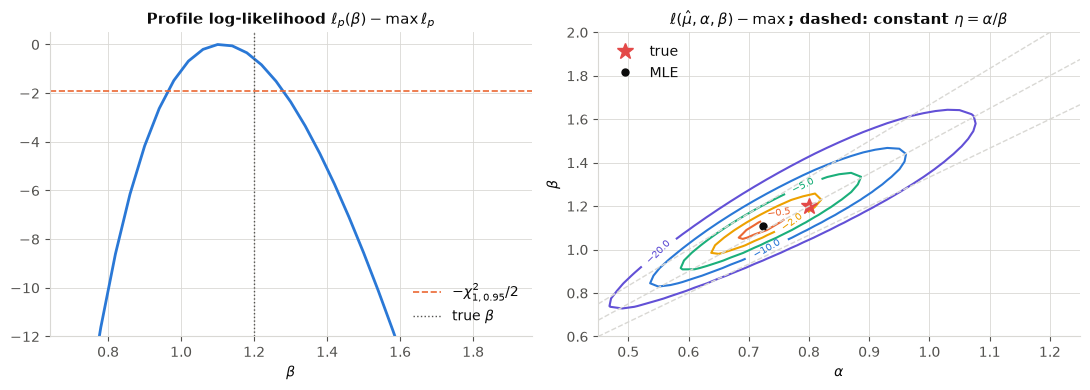

In [2]:

betas = np.linspace(0.7, 1.9, 31)
prof = []
for b in betas:
    r = optimize.minimize(lambda x: negloglik((x[0], x[1], b), t, T)[0], th[:2], method="L-BFGS-B",
                          jac=lambda x: negloglik((x[0], x[1], b), t, T)[1][:2], bounds=[(1e-6, None), (1e-8, None)])
    prof.append(-r.fun)
prof = np.array(prof)
aa, bb = np.meshgrid(np.linspace(0.45, 1.25, 41), np.linspace(0.6, 2.0, 41))
Z = np.array([[-negloglik((th[0], a_, b_), t, T)[0] for a_, b_ in zip(ra, rb)] for ra, rb in zip(aa, bb)])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(betas, prof - prof.max(), color=BLUE, lw=2)
ax[0].axhline(-1.92, color=ORANGE, ls="--", lw=1.2, label=r"$-\chi^2_{1, 0.95}/2$")
ax[0].axvline(true[2], color=MUTED, ls=":", lw=1, label=r"true $\beta$")
ax[0].set(title=r"Profile log-likelihood $\ell_p(\beta) - \max\ell_p$", xlabel=r"$\beta$", ylim=(-12, 0.5)); ax[0].legend()
cs = ax[1].contour(aa, bb, Z - Z.max(), levels=[-20, -10, -5, -2, -0.5], colors=[VIOLET, BLUE, AQUA, YELLOW, ORANGE])
ax[1].clabel(cs, fontsize=7)
ax[1].plot(*true[1:], "*", color=RED, ms=12, label="true")
ax[1].plot(th[1], th[2], "o", color=INK, ms=5, label="MLE")
for eta in [0.6, 2 / 3, 0.75]:
    ax[1].plot(aa[0], aa[0] / eta, color=GRID, lw=1, ls="--")
ax[1].set(title=r"$\ell(\hat\mu, \alpha, \beta) - \max$; dashed: constant $\eta = \alpha/\beta$", xlabel=r"$\alpha$", ylabel=r"$\beta$", xlim=(0.45, 1.25), ylim=(0.6, 2.0))
ax[1].legend(loc="upper left")
plt.tight_layout(); plt.show()


**Sampling distribution.** $200$ independent data sets of length $T = 1000$, each fitted by maximum likelihood. The histograms are compared with the normal approximation centred at the truth with the average estimated standard error; the coverage of the nominal $95\%$ intervals $\hat\vartheta \pm 1.96\,\widehat{\mathrm{se}}$ is printed below.

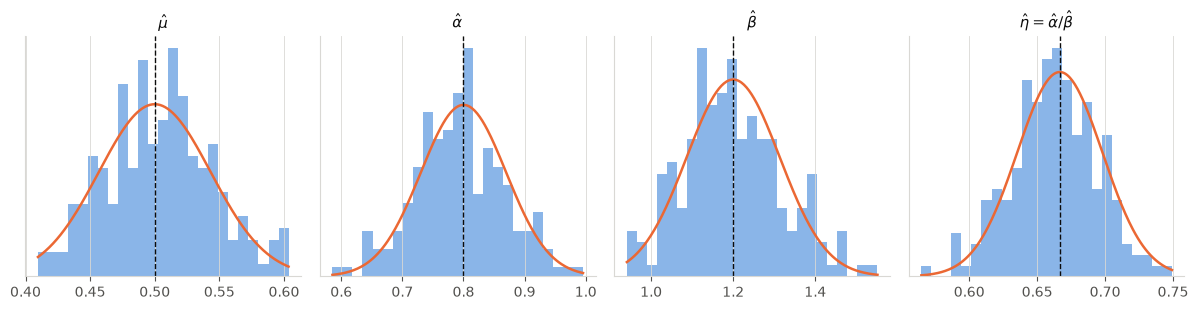

coverage of 95% intervals (mu, alpha, beta): [0.965 0.935 0.93 ]
mean estimates: [0.504 0.793 1.2  ]  true: [0.5 0.8 1.2]


In [3]:

rng = np.random.default_rng(7)
est, ses = [], []
for _ in range(200):
    tt = sim_exact(*true, 1000.0, rng, burn=100.0)
    x, _ = fit_mle(tt, 1000.0)
    est.append(x); ses.append(std_errors(x, tt, 1000.0))
est, ses = np.array(est), np.array(ses)
fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
names = [r"$\hat\mu$", r"$\hat\alpha$", r"$\hat\beta$", r"$\hat\eta = \hat\alpha/\hat\beta$"]
vals = [est[:, 0], est[:, 1], est[:, 2], est[:, 1] / est[:, 2]]
truths = [*true, true[1] / true[2]]
for k, (a, nm, v, tr) in enumerate(zip(ax, names, vals, truths)):
    a.hist(v, bins=25, density=True, color=BLUE, alpha=0.55)
    sd = ses[:, k].mean() if k < 3 else np.std(v)
    x = np.linspace(v.min(), v.max(), 200)
    a.plot(x, stats.norm.pdf(x, tr, sd), color=ORANGE, lw=1.8)
    a.axvline(tr, color=INK, ls="--", lw=1); a.set_title(nm); a.set_yticks([])
plt.tight_layout(); plt.show()
cover = np.mean(np.abs(est - true) <= 1.96 * ses, axis=0)
print("coverage of 95% intervals (mu, alpha, beta):", np.round(cover, 3))
print("mean estimates:", np.round(est.mean(0), 3), " true:", true)


**EM and declustering.** On the first data set we run EM from a deliberately poor start ($\mu = 1$, $\eta = 0.2$, $\beta = 3$). Pairs further apart than $40$ time units are ignored ($e^{-40\beta}$ is negligible for every $\beta$ visited). The log-likelihood increases at every iteration and converges to the maximum likelihood value. The branching probabilities then split the intensity into its exogenous and endogenous parts.

EM:  mu = 0.540, alpha = 0.728, beta = 1.120   |  MLE: mu = 0.538, alpha = 0.724, beta = 1.111
log-likelihood: EM -1178.605, MLE -1178.597;  log-likelihood ever decreased: False
estimated exogenous fraction mean(p_i0) = 0.350   (1 - eta_hat = 0.350)


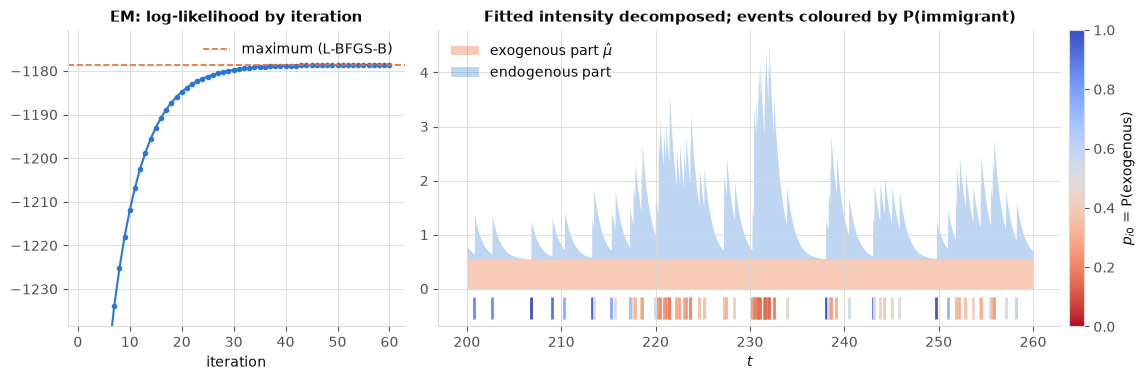

In [4]:

def pairs(t, dmax):
    I, J = [], []
    for i in range(len(t)):
        j0 = np.searchsorted(t, t[i] - dmax)
        I.append(np.full(i - j0, i)); J.append(np.arange(j0, i))
    I, J = np.concatenate(I), np.concatenate(J)
    return I, J, t[I] - t[J]

def em(t, T, mu, eta, beta, iters=60, dmax=40.0):
    I, J, d = pairs(t, dmax); n = len(t); s = T - t; trace = []
    for _ in range(iters):
        phi = eta * beta * np.exp(-beta * d)
        lam = mu + np.bincount(I, phi, minlength=n)
        trace.append(np.sum(np.log(lam)) - mu * T - eta * np.sum(1 - np.exp(-beta * s)))
        p0, pij = mu / lam, phi / lam[I]
        P, Dsum = pij.sum(), np.sum(pij * d)
        mu = p0.sum() / T
        beta = optimize.minimize_scalar(lambda b: -(-P * np.log(np.sum(1 - np.exp(-b * s))) + P * np.log(b) - b * Dsum),
                                        bounds=(1e-3, 50), method="bounded").x
        eta = P / np.sum(1 - np.exp(-beta * s))
    return (mu, eta, beta), np.array(trace), p0

(mu_e, eta_e, beta_e), trace, p0 = em(t, T, 1.0, 0.2, 3.0)
print(f"EM:  mu = {mu_e:.3f}, alpha = {eta_e*beta_e:.3f}, beta = {beta_e:.3f}   |  MLE: mu = {th[0]:.3f}, alpha = {th[1]:.3f}, beta = {th[2]:.3f}")
print(f"log-likelihood: EM {trace[-1]:.3f}, MLE {ll_hat:.3f};  log-likelihood ever decreased: {bool(np.any(np.diff(trace) < -1e-8))}")
print(f"estimated exogenous fraction mean(p_i0) = {p0.mean():.3f}   (1 - eta_hat = {1 - eta_e:.3f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1, 2.2]})
ax[0].plot(np.arange(1, len(trace) + 1), trace, "o-", color=BLUE, ms=3)
ax[0].axhline(ll_hat, color=ORANGE, ls="--", lw=1.2, label="maximum (L-BFGS-B)")
ax[0].set(title="EM: log-likelihood by iteration", xlabel="iteration", ylim=(ll_hat - 60, ll_hat + 8)); ax[0].legend()
win = (t > 200) & (t < 260)
g = np.linspace(200, 260, 3000)
dd = g[:, None] - t[None, :]
endo = (eta_e * beta_e * np.exp(-beta_e * np.where(dd > 0, dd, np.inf))).sum(1)
ax[1].fill_between(g, 0, mu_e, color=ORANGE, alpha=0.35, lw=0, label=r"exogenous part $\hat\mu$")
ax[1].fill_between(g, mu_e, mu_e + endo, color=BLUE, alpha=0.3, lw=0, label="endogenous part")
sc = ax[1].scatter(t[win], np.full(win.sum(), -0.35), c=p0[win], cmap="coolwarm_r", vmin=0, vmax=1, marker="|", s=250, lw=2)
plt.colorbar(sc, ax=ax[1], pad=0.01, label=r"$p_{i0}$ = P(exogenous)")
ax[1].set(title="Fitted intensity decomposed; events coloured by P(immigrant)", xlabel="$t$", ylim=(-0.7, None)); ax[1].legend(loc="upper left")
plt.tight_layout(); plt.show()


**Binned data.** Now suppose only counts in bins of width $\tau = 0.5$ are available. For $50$ data sets of length $T = 5000$ (with burn-in, so that the moment formulas apply) we compare the binned method-of-moments estimator (@def-gmm-hawkes, with the mean, the variance and $5$ autocovariances) with the MLE computed from the exact event times.

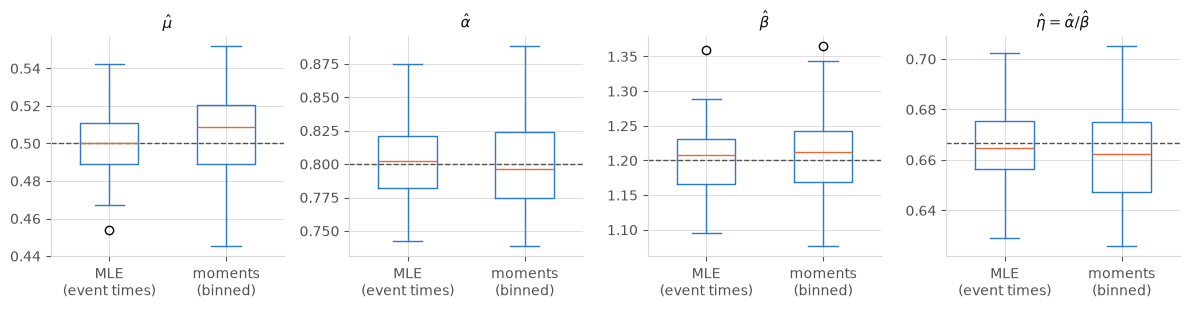

root mean squared error (mu, alpha, beta):
  MLE     : [0.019 0.031 0.048]
  moments : [0.025 0.037 0.064]


In [5]:

def moments_theory(mu, a, b, tau, dmax):
    k = b - a; lbar = b * mu / k
    w1 = lbar * tau
    w2 = lbar * (b**2 / k**2 * tau + (1 - b**2 / k**2) * (1 - np.exp(-k * tau)) / k)
    d = np.arange(1, dmax + 1)
    w3 = lbar * a * (2 * b - a) / (2 * k**3) * (1 - np.exp(-k * tau))**2 * np.exp(-k * (d - 1) * tau)
    return np.r_[w1, w2, w3]

def moments_sample(K, dmax):
    Kc = K - K.mean()
    return np.r_[K.mean(), K.var(), [np.mean(Kc[:-d] * Kc[d:]) for d in range(1, dmax + 1)]]

def fit_gmm(K, tau, dmax=5):
    m = moments_sample(K, dmax)
    def obj(z):                                  # mu = e^z0, beta = e^z2, alpha = beta * logistic(z1) < beta
        mu, b = np.exp(z[0]), np.exp(z[2]); a = b / (1 + np.exp(-z[1]))
        return np.sum(((m - moments_theory(mu, a, b, tau, dmax)) / m) ** 2)
    best = min((optimize.minimize(obj, z0, method="Nelder-Mead", options={"xatol": 1e-8, "fatol": 1e-12, "maxiter": 4000})
                for z0 in [(np.log(0.5), 0.0, 0.0), (np.log(0.2), 1.5, 1.0), (np.log(1.0), -1.0, -0.5)]), key=lambda r: r.fun)
    mu, b = np.exp(best.x[0]), np.exp(best.x[2]); return np.array([mu, b / (1 + np.exp(-best.x[1])), b])

rng = np.random.default_rng(3)
tau, T5 = 0.5, 5000.0
G, Mle = [], []
for _ in range(50):
    tt = sim_exact(*true, T5, rng, burn=200.0)
    K = np.bincount((tt // tau).astype(int), minlength=int(T5 / tau))[: int(T5 / tau)]
    G.append(fit_gmm(K, tau)); Mle.append(fit_mle(tt, T5)[0])
G, Mle = np.array(G), np.array(Mle)
fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
for k, (a, nm) in enumerate(zip(ax, names)):
    vg = G[:, k] if k < 3 else G[:, 1] / G[:, 2]; vm = Mle[:, k] if k < 3 else Mle[:, 1] / Mle[:, 2]
    a.boxplot([vm, vg], tick_labels=["MLE\n(event times)", "moments\n(binned)"], widths=0.5,
              medianprops={"color": ORANGE}, boxprops={"color": BLUE}, whiskerprops={"color": BLUE}, capprops={"color": BLUE})
    a.axhline(truths[k], color=MUTED, ls="--", lw=1); a.set_title(nm)
plt.tight_layout(); plt.show()
print("root mean squared error (mu, alpha, beta):")
print("  MLE     :", np.round(np.sqrt(np.mean((Mle - true) ** 2, 0)), 3))
print("  moments :", np.round(np.sqrt(np.mean((G - true) ** 2, 0)), 3))


**Model checking and kernel choice.** Finally, data generated with a **power-law** kernel $\varphi(t) = K(t + c)^{-p}$ ($c = 0.1$, $p = 1.6$, $\eta = 0.7$, $\mu = 0.3$) are fitted with three models: a Poisson process, an exponential Hawkes process, and the power-law Hawkes process (four parameters $\mu, \eta, c, p$, fitted with the $O(n^2)$ likelihood). The residual QQ plots and AIC values show the Poisson model failing badly, the exponential kernel capturing most of the clustering but misfitting the long gaps, and the correct kernel passing.

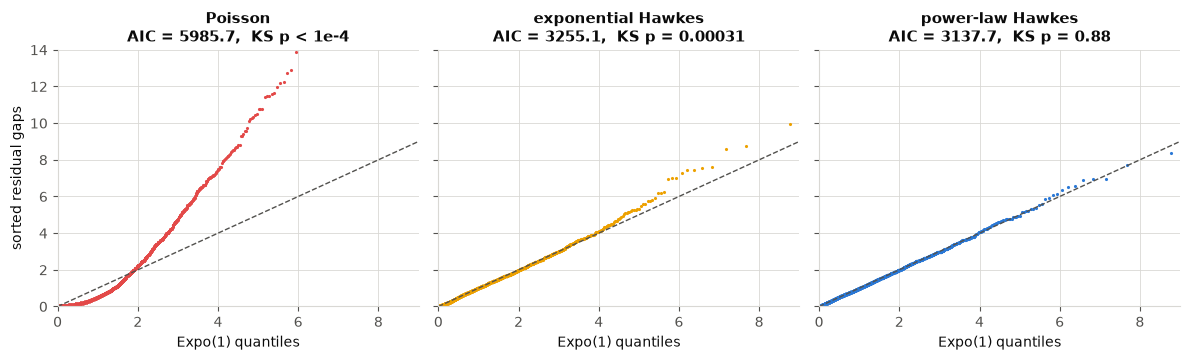

n = 3224;  power-law fit: mu = 0.330, eta = 0.695, c = 0.115, p = 1.660  (true 0.3, 0.7, 0.1, 1.6)
exponential fit: eta = 0.561, beta = 4.336


In [6]:

c0, p0_, eta0, mu0 = 0.1, 1.6, 0.7, 0.3
def ogata_general(mu, phi, T, rng):
    t, ev = 0.0, np.empty(0)
    while True:
        M = mu + phi(t - ev).sum()
        t += rng.exponential(1 / M)
        if t > T: return ev
        if rng.random() * M <= mu + phi(t - ev).sum(): ev = np.append(ev, t)

pl = lambda x, eta, c, p: eta * (p - 1) * c ** (p - 1) * (x + c) ** (-p)
PL = lambda x, eta, c, p: eta * (1 - (c / (x + c)) ** (p - 1))          # integral of pl from 0 to x
rng = np.random.default_rng(17)
Tp = 3000.0
tp = ogata_general(mu0, lambda x: pl(x, eta0, c0, p0_), Tp, rng)
n = len(tp)
Dm = tp[:, None] - tp[None, :]; low = np.tril(np.ones((n, n), bool), -1); dpairs = Dm[low]; ipairs = np.nonzero(low)[0]

def nll_pl(z):
    mu, eta, c, p = np.exp(z[0]), 1 / (1 + np.exp(-z[1])), np.exp(z[2]), 1 + np.exp(z[3])
    lam = mu + np.bincount(ipairs, pl(dpairs, eta, c, p), minlength=n)
    return -(np.sum(np.log(lam)) - mu * Tp - np.sum(PL(Tp - tp, eta, c, p)))

rp = optimize.minimize(nll_pl, [np.log(0.5), 0.0, np.log(0.5), np.log(0.5)], method="Nelder-Mead",
                       options={"maxiter": 3000, "xatol": 1e-6, "fatol": 1e-8})
mu_p, eta_p, c_p, p_p = np.exp(rp.x[0]), 1 / (1 + np.exp(-rp.x[1])), np.exp(rp.x[2]), 1 + np.exp(rp.x[3])
the, ll_e = fit_mle(tp, Tp)
ll_po = n * np.log(n / Tp) - n

# residual gaps = compensator increments
Lam_po = tp * n / Tp
Lam_e = the[0] * tp + the[1] / the[2] * np.array([np.sum(1 - np.exp(-the[2] * (x - tp[tp < x]))) for x in tp])
Lam_p = mu_p * tp + np.array([np.sum(PL(x - tp[tp < x], eta_p, c_p, p_p)) for x in tp])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.7), sharey=True)
q = (np.arange(1, n + 1) - 0.5) / n
for a, (nm, L, ll, k), c in zip(ax, [("Poisson", Lam_po, ll_po, 1), ("exponential Hawkes", Lam_e, ll_e, 3), ("power-law Hawkes", Lam_p, -rp.fun, 4)], [RED, YELLOW, BLUE]):
    r = np.diff(np.r_[0, L])
    a.plot(-np.log(1 - q), np.sort(r), ".", ms=2.5, color=c); a.plot([0, 9], [0, 9], color=MUTED, ls="--", lw=1)
    pv = stats.kstest(r, "expon").pvalue
    a.set(title=f"{nm}\nAIC = {-2*ll + 2*k:.1f},  KS p = {pv:.2g}" if pv > 1e-4 else f"{nm}\nAIC = {-2*ll + 2*k:.1f},  KS p < 1e-4",
          xlabel="Expo(1) quantiles", xlim=(0, 9), ylim=(0, 14))
ax[0].set_ylabel("sorted residual gaps")
plt.tight_layout(); plt.show()
print(f"n = {n};  power-law fit: mu = {mu_p:.3f}, eta = {eta_p:.3f}, c = {c_p:.3f}, p = {p_p:.3f}  (true 0.3, 0.7, 0.1, 1.6)")
print(f"exponential fit: eta = {the[1]/the[2]:.3f}, beta = {the[2]:.3f}")